In [ ]:
!nvidia-smi

Tue Oct 27 16:48:35 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   61C    P8             12W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
# To use my one of pre-made dataset instead of your own custom dataset, download it here (control which dataset is downloaded by commenting out either line)
!wget -O /content/data.zip https://s3.us-west-1.amazonaws.com/evanjuras.com/resources/candy_data_06JAN25.zip # Candy dataset
#!wget -O /content/data.zip https://s3.us-west-1.amazonaws.com/evanjuras.com/resources/YOLO_coin_data_12DEC30.zip # Coin dataset

--2026-10-27 17:21:41--  https://s3.us-west-1.amazonaws.com/evanjuras.com/resources/candy_data_06JAN25.zip
Resolving s3.us-west-1.amazonaws.com (s3.us-west-1.amazonaws.com)... 16.15.0.202, 16.15.4.43, 16.15.4.90, ...
Connecting to s3.us-west-1.amazonaws.com (s3.us-west-1.amazonaws.com)|16.15.0.202|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 45172966 (43M) [application/zip]
Saving to: ‘/content/data.zip’

/content/data.zip   100%[===================>]  43.08M  14.1MB/s    in 3.1s    

2026-10-27 17:21:45 (14.1 MB/s) - ‘/content/data.zip’ saved [45172966/45172966]



In [ ]:
# Unzip images to a custom data folder
!unzip -q /content/data.zip -d /content/custom_data

In [ ]:
!wget -O /content/train_val_split.py https://raw.githubusercontent.com/EdjeElectronics/Train-and-Deploy-YOLO-Models/refs/heads/main/utils/train_val_split.py

# TO DO: Improve robustness of train_val_split.py script so it can handle nested data folders, etc
!python train_val_split.py --datapath="/content/custom_data" --train_pct=0.9

--2026-10-27 17:21:16--  https://raw.githubusercontent.com/EdjeElectronics/Train-and-Deploy-YOLO-Models/refs/heads/main/utils/train_val_split.py
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 3203 (3.1K) [text/plain]
Saving to: ‘/content/train_val_split.py’

/content/train_val_ 100%[===================>]   3.13K  --.-KB/s    in 0s      

2026-10-27 17:21:16 (40.2 MB/s) - ‘/content/train_val_split.py’ saved [3203/3203]

Directory specified by --datapath not found. Verify the path is correct (and uses double back slashes if on Windows) and try again.


In [ ]:
!pip install ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 14.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [ultralytics]


In [ ]:
# Python function to automatically create data.yaml config file
# 1. Reads "classes.txt" file to get list of class names
# 2. Creates data dictionary with correct paths to folders, number of classes, and names of classes
# 3. Writes data in YAML format to data.yaml

import yaml
import os

def create_data_yaml(path_to_classes_txt, path_to_data_yaml):

  # Read class.txt to get class names
  if not os.path.exists(path_to_classes_txt):
    print(f'classes.txt file not found! Please create a classes.txt labelmap and move it to {path_to_classes_txt}')
    return
  with open(path_to_classes_txt, 'r') as f:
    classes = []
    for line in f.readlines():
      if len(line.strip()) == 0: continue
      classes.append(line.strip())
  number_of_classes = len(classes)

  # Create data dictionary
  data = {
      'path': '/content/data',
      'train': 'train/images',
      'val': 'validation/images',
      'nc': number_of_classes,
      'names': classes
  }

  # Write data to YAML file
  with open(path_to_data_yaml, 'w') as f:
    yaml.dump(data, f, sort_keys=False)
  print(f'Created config file at {path_to_data_yaml}')

  return

# Define path to classes.txt and run function
path_to_classes_txt = '/content/custom_data/classes.txt'
path_to_data_yaml = '/content/data.yaml'

create_data_yaml(path_to_classes_txt, path_to_data_yaml)

print('\nFile contents:\n')
!cat /content/data.yaml

Created config file at /content/data.yaml

File contents:

path: /content/data
train: train/images
val: validation/images
nc: 11
names:
- MMs_peanut
- MMs_regular
- airheads
- gummy_worms
- milky_way
- nerds
- skittles
- snickers
- starbust
- three_musketeers
- twizzlers


In [ ]:
# 1. Rename the custom_data folder to data (as expected by data.yaml)
import os
if os.path.exists('/content/custom_data') and not os.path.exists('/content/data'):
    os.rename('/content/custom_data', '/content/data')

# 2. Run the split script on the correct path
!python /content/train_val_split.py --datapath="/content/data" --train_pct=0.9

# 3. Start training
!yolo detect train data=/content/data.yaml model=yolo11s.pt epochs=60 imgsz=640

Created folder at /content/data/train/images.
Created folder at /content/data/train/labels.
Created folder at /content/data/validation/images.
Created folder at /content/data/validation/labels.
Number of image files: 162
Number of annotation files: 162
Images moving to train: 145
Images moving to validation: 17
Ultralytics 8.4.190 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fract

In [ ]:
import os
# Find the latest training run directory in /content/runs/detect/
runs = [os.path.join('/content/runs/detect', d) for d in os.listdir('/content/runs/detect') if d.startswith('train')]
latest_run = max(runs, key=os.path.getmtime) if runs else '/content/runs/detect/train'
best_weights = os.path.join(latest_run, 'weights/best.pt')

print(f"Using latest weights from: {best_weights}")
!yolo detect predict model={best_weights} source=data/validation/images save=True

Using latest weights from: /content/runs/detect/train-3/weights/best.pt
Ultralytics 8.4.190 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s summary (fused): 100 layers, 9,417,057 parameters, 0 gradients, 21.4 GFLOPs

image 1/17 /content/data/validation/images/0425e3c8-candy_59.jpg: 384x640 1 MMs_peanut, 1 MMs_regular, 2 airheadss, 1 gummy_worms, 1 skittles, 1 snickers, 16.2ms
image 2/17 /content/data/validation/images/0873acf3-candy_40.jpg: 384x640 1 MMs_peanut, 1 airheads, 1 skittles, 1 twizzlers, 16.2ms
image 3/17 /content/data/validation/images/158c744d-candy_123.jpg: 384x640 1 airheads, 16.3ms
image 4/17 /content/data/validation/images/459c5d1e-candy_25.jpg: 384x640 1 gummy_worms, 1 skittles, 16.1ms
image 5/17 /content/data/validation/images/48402bcc-candy_39.jpg: 384x640 2 MMs_peanuts, 2 MMs_regulars, 1 airheads, 1 gummy_worms, 1 milky_way, 2 twizzlerss, 16.1ms
image 6/17 /content/data/validation/images/516476d5-candy_115.jpg: 480x640 1 MMs_peanut, 1 airhea

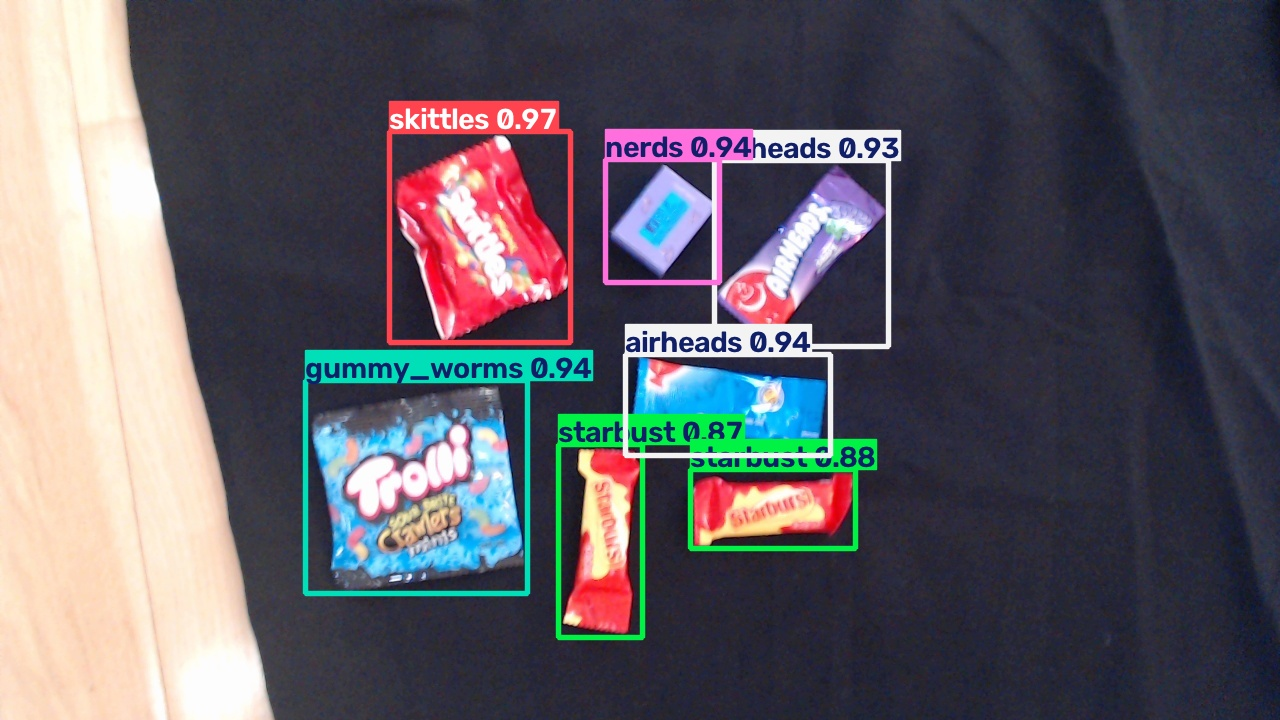

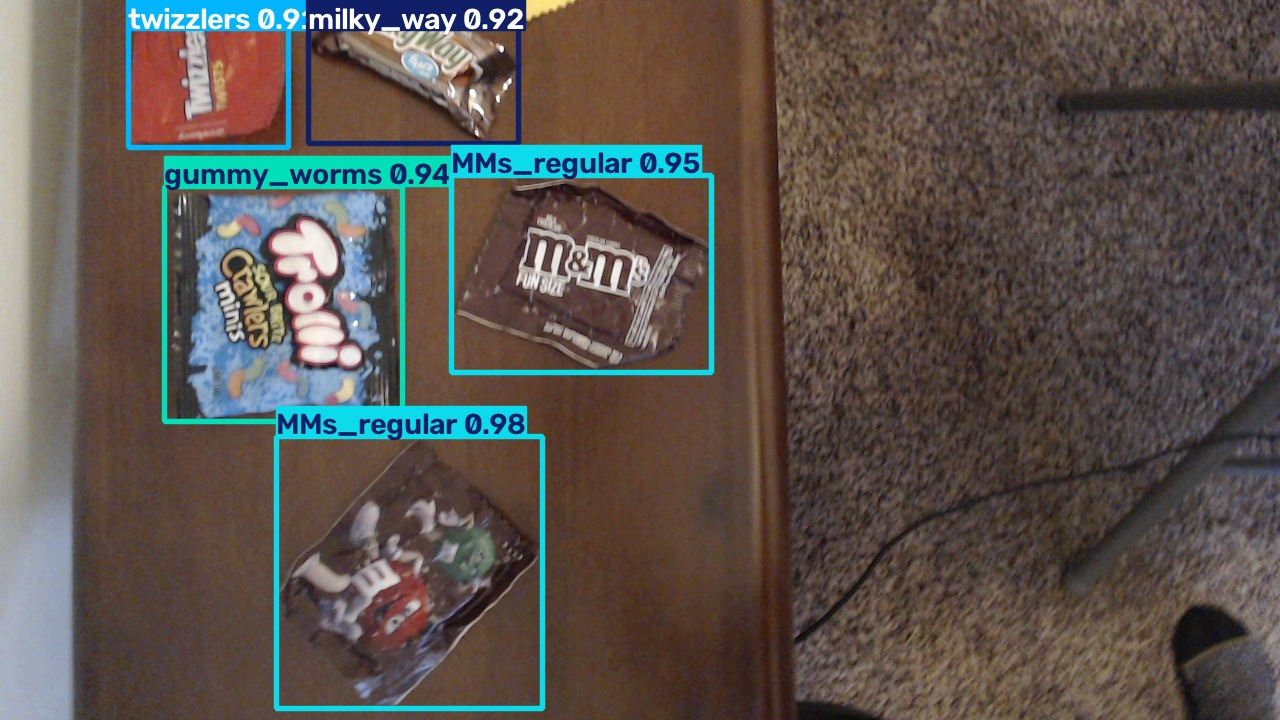

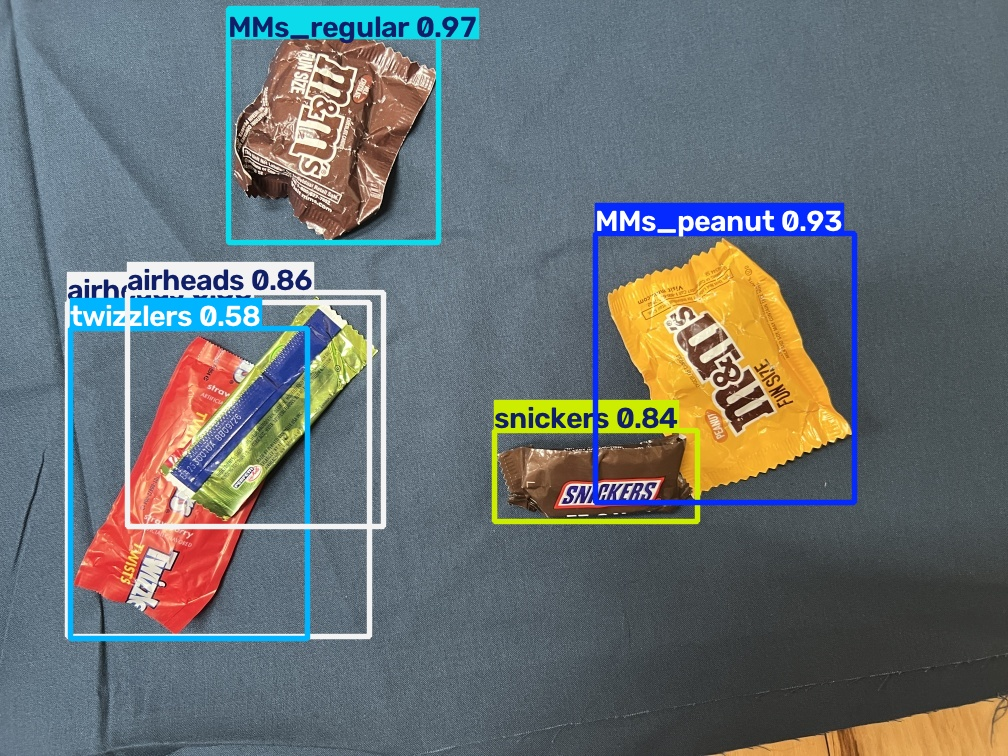

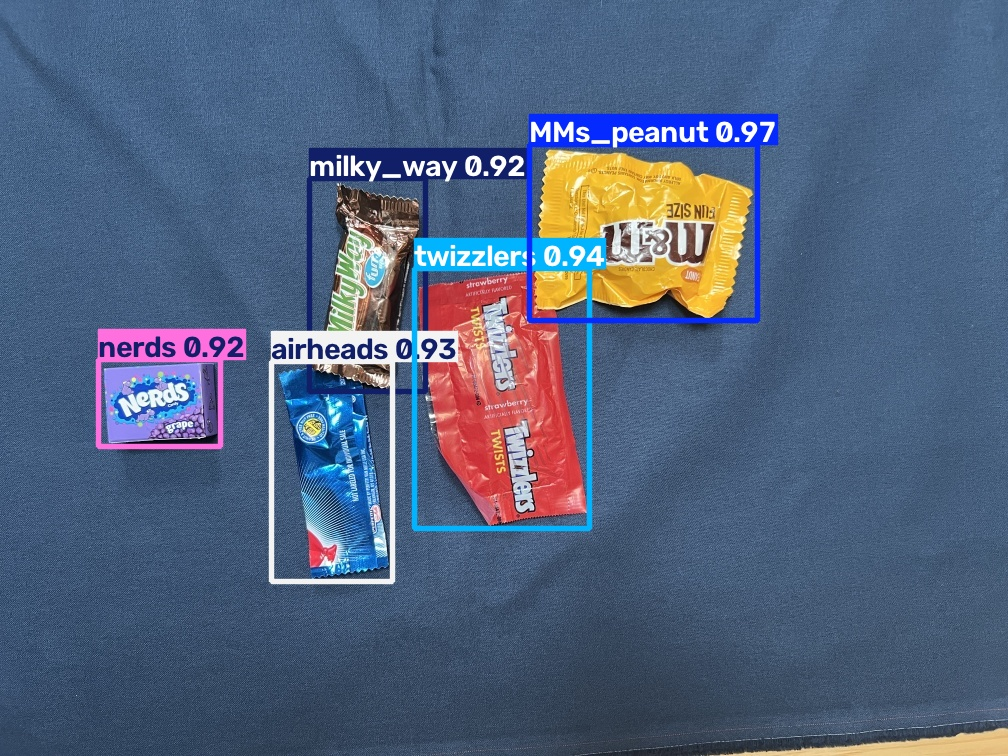

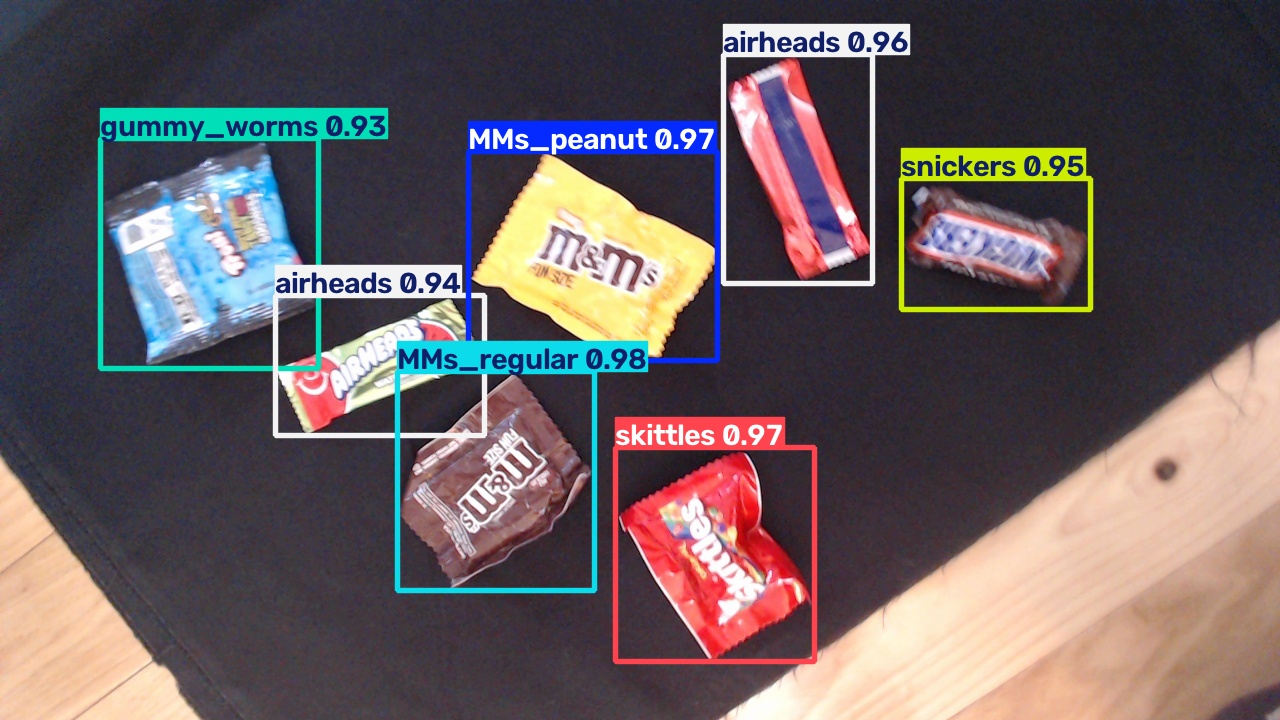

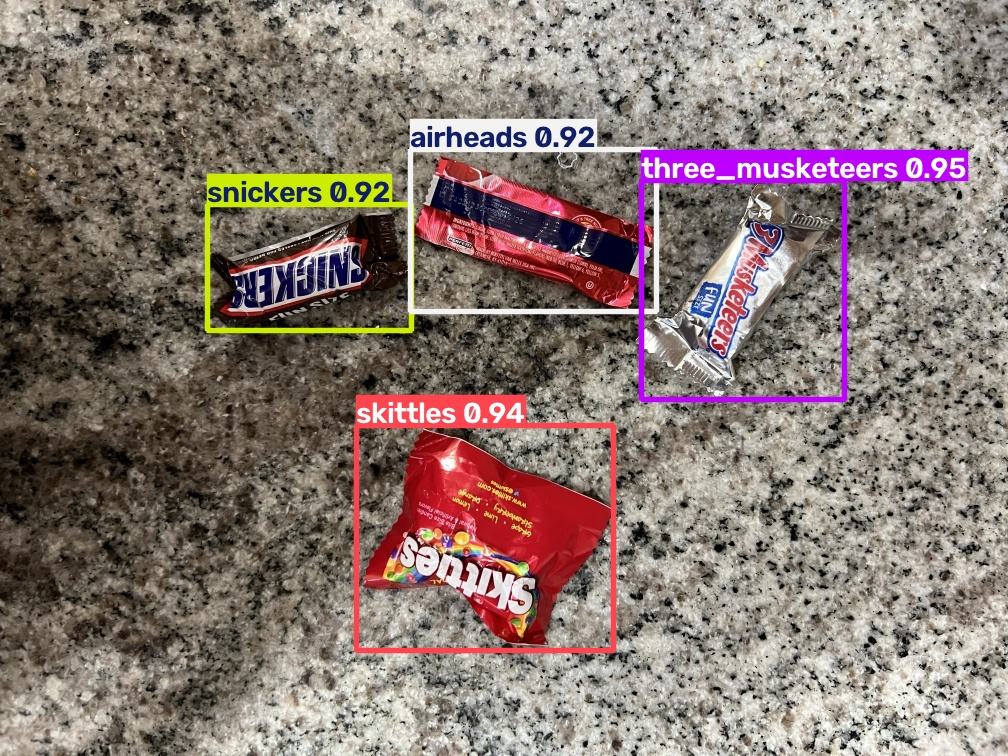

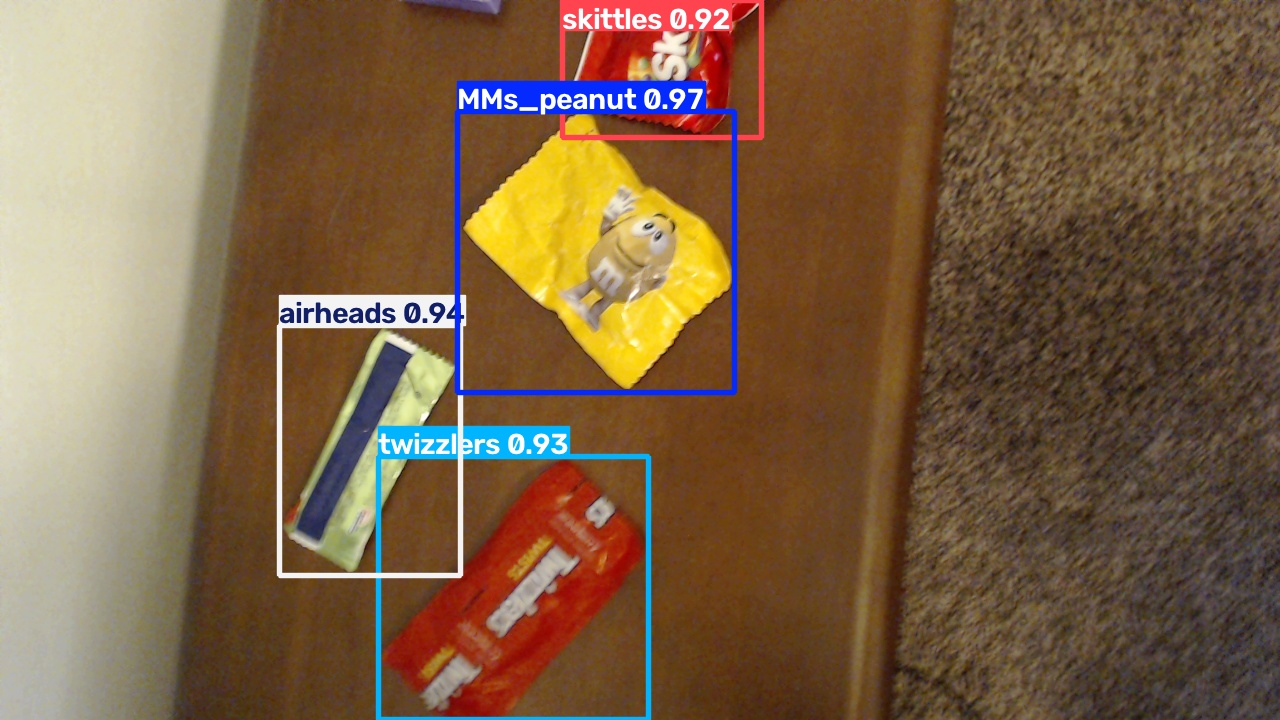

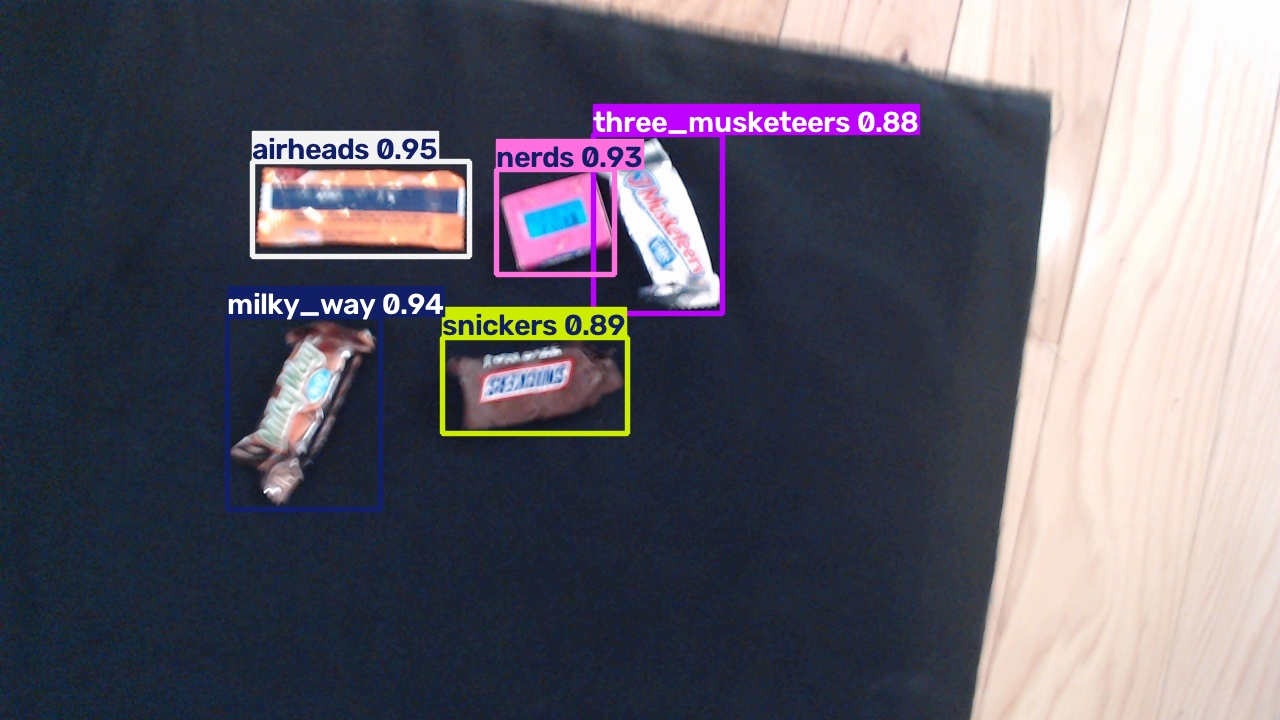

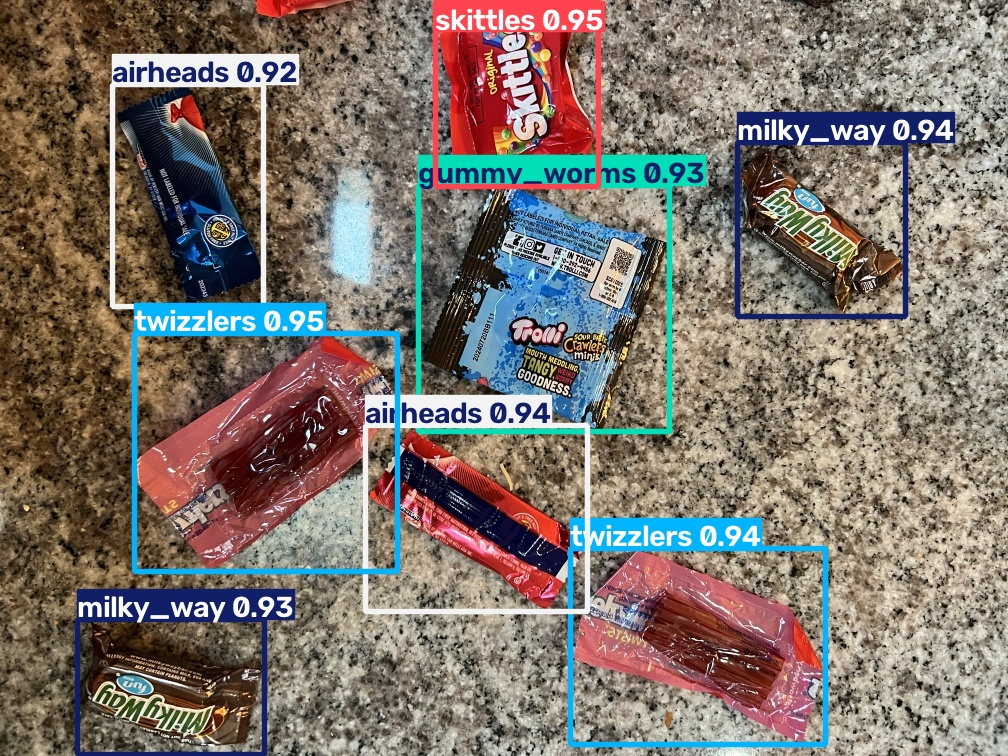

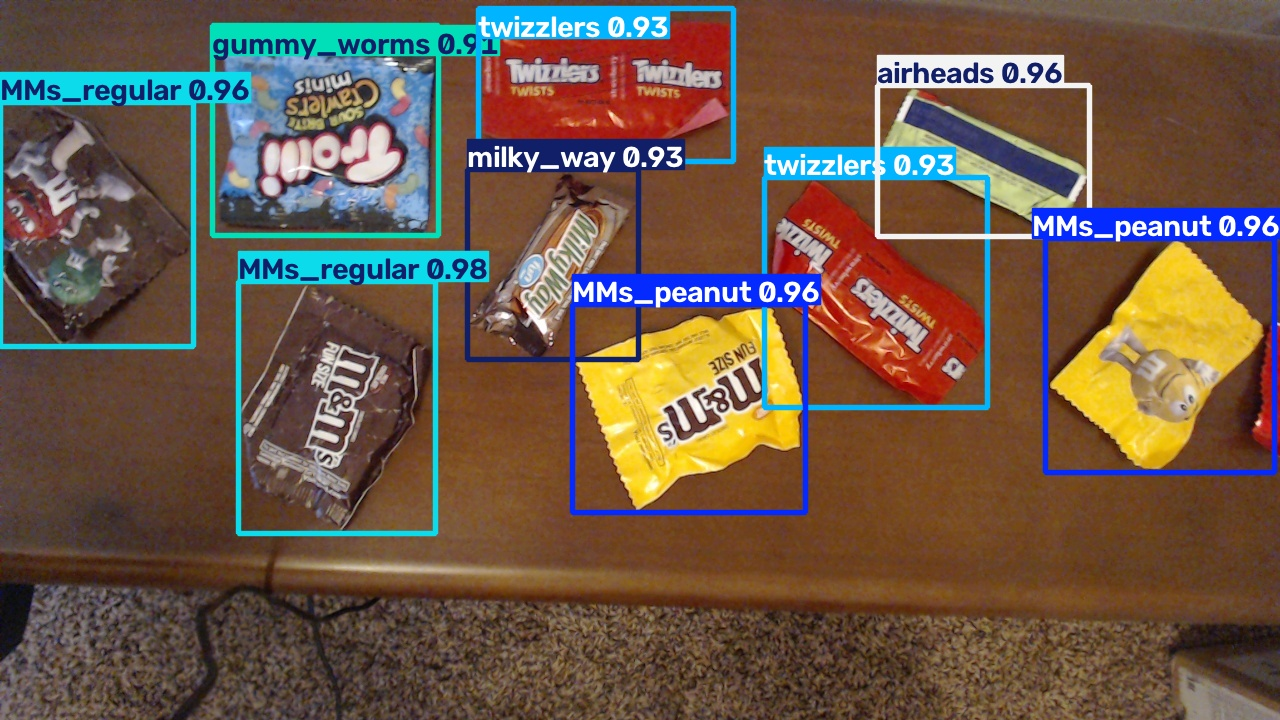

In [ ]:
import glob
from IPython.display import Image, display
for image_path in glob.glob(f'/content/runs/detect/predict/*.jpg')[:10]:
  display(Image(filename=image_path, height=400))
  print('\n')


In [ ]:
import os
# Find the latest training run directory
runs = [os.path.join('/content/runs/detect', d) for d in os.listdir('/content/runs/detect') if d.startswith('train')]
latest_run = max(runs, key=os.path.getmtime) if runs else '/content/runs/detect/train'
best_weights = os.path.join(latest_run, 'weights/best.pt')

# Create "my_model" folder to store model weights and train results
!mkdir -p /content/my_model
!cp {best_weights} /content/my_model/my_model.pt
!cp -r {latest_run} /content/my_model/train

# Zip into "my_model.zip"
%cd /content/my_model
!zip /content/my_model.zip my_model.pt
!zip -r /content/my_model.zip train
%cd /content

/content/my_model
  adding: my_model.pt (deflated 8%)
  adding: train/ (stored 0%)
  adding: train/weights/ (stored 0%)
  adding: train/weights/last.pt (deflated 8%)
  adding: train/weights/best.pt (deflated 8%)
  adding: train/BoxR_curve.png (deflated 10%)
  adding: train/BoxF1_curve.png (deflated 8%)
  adding: train/results.csv (deflated 63%)
  adding: train/confusion_matrix.png (deflated 19%)
  adding: train/train_batch502.jpg (deflated 11%)
  adding: train/confusion_matrix_normalized.png (deflated 18%)
  adding: train/train_batch500.jpg (deflated 9%)
  adding: train/args.yaml (deflated 53%)
  adding: train/train_batch0.jpg (deflated 5%)
  adding: train/train_batch2.jpg (deflated 4%)
  adding: train/train_batch501.jpg (deflated 14%)
  adding: train/results.png (deflated 7%)
  adding: train/val_batch0_labels.jpg (deflated 7%)
  adding: train/BoxPR_curve.png (deflated 19%)
  adding: train/val_batch0_pred.jpg (deflated 7%)
  adding: train/train_batch1.jpg (deflated 5%)
  adding: train/

In [ ]:
import os
# Find the latest training run directory automatically
runs = [os.path.join('/content/runs/detect', d) for d in os.listdir('/content/runs/detect') if d.startswith('train')]
latest_run = max(runs, key=os.path.getmtime) if runs else '/content/runs/detect/train'
best_weights = os.path.join(latest_run, 'weights/best.pt')

print(f"Using latest weights from: {best_weights}")
# Run prediction on your validation images using CPU/GPU automatically
!yolo detect predict model={best_weights} source=/content/data/validation/images save=True

Using latest weights from: /content/runs/detect/train-3/weights/best.pt
Ultralytics 8.4.190 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s summary (fused): 100 layers, 9,417,057 parameters, 0 gradients, 21.4 GFLOPs

image 1/17 /content/data/validation/images/0425e3c8-candy_59.jpg: 384x640 1 MMs_peanut, 1 MMs_regular, 2 airheadss, 1 gummy_worms, 1 skittles, 1 snickers, 16.2ms
image 2/17 /content/data/validation/images/0873acf3-candy_40.jpg: 384x640 1 MMs_peanut, 1 airheads, 1 skittles, 1 twizzlers, 16.2ms
image 3/17 /content/data/validation/images/158c744d-candy_123.jpg: 384x640 1 airheads, 16.1ms
image 4/17 /content/data/validation/images/459c5d1e-candy_25.jpg: 384x640 1 gummy_worms, 1 skittles, 16.1ms
image 5/17 /content/data/validation/images/48402bcc-candy_39.jpg: 384x640 2 MMs_peanuts, 2 MMs_regulars, 1 airheads, 1 gummy_worms, 1 milky_way, 2 twizzlerss, 16.1ms
image 6/17 /content/data/validation/images/516476d5-candy_115.jpg: 480x640 1 MMs_peanut, 1 airhea


image 1/1 /content/data/images/09563069-candy_12.jpg: 384x640 1 nerds, 1 skittles, 2 snickerss, 16.0ms
Speed: 2.7ms preprocess, 16.0ms inference, 1.3ms postprocess per image at shape (1, 3, 384, 640)
Results saved to /content/runs/detect/my_predictions
Result saved to: /content/runs/detect/my_predictions/09563069-candy_12.jpg


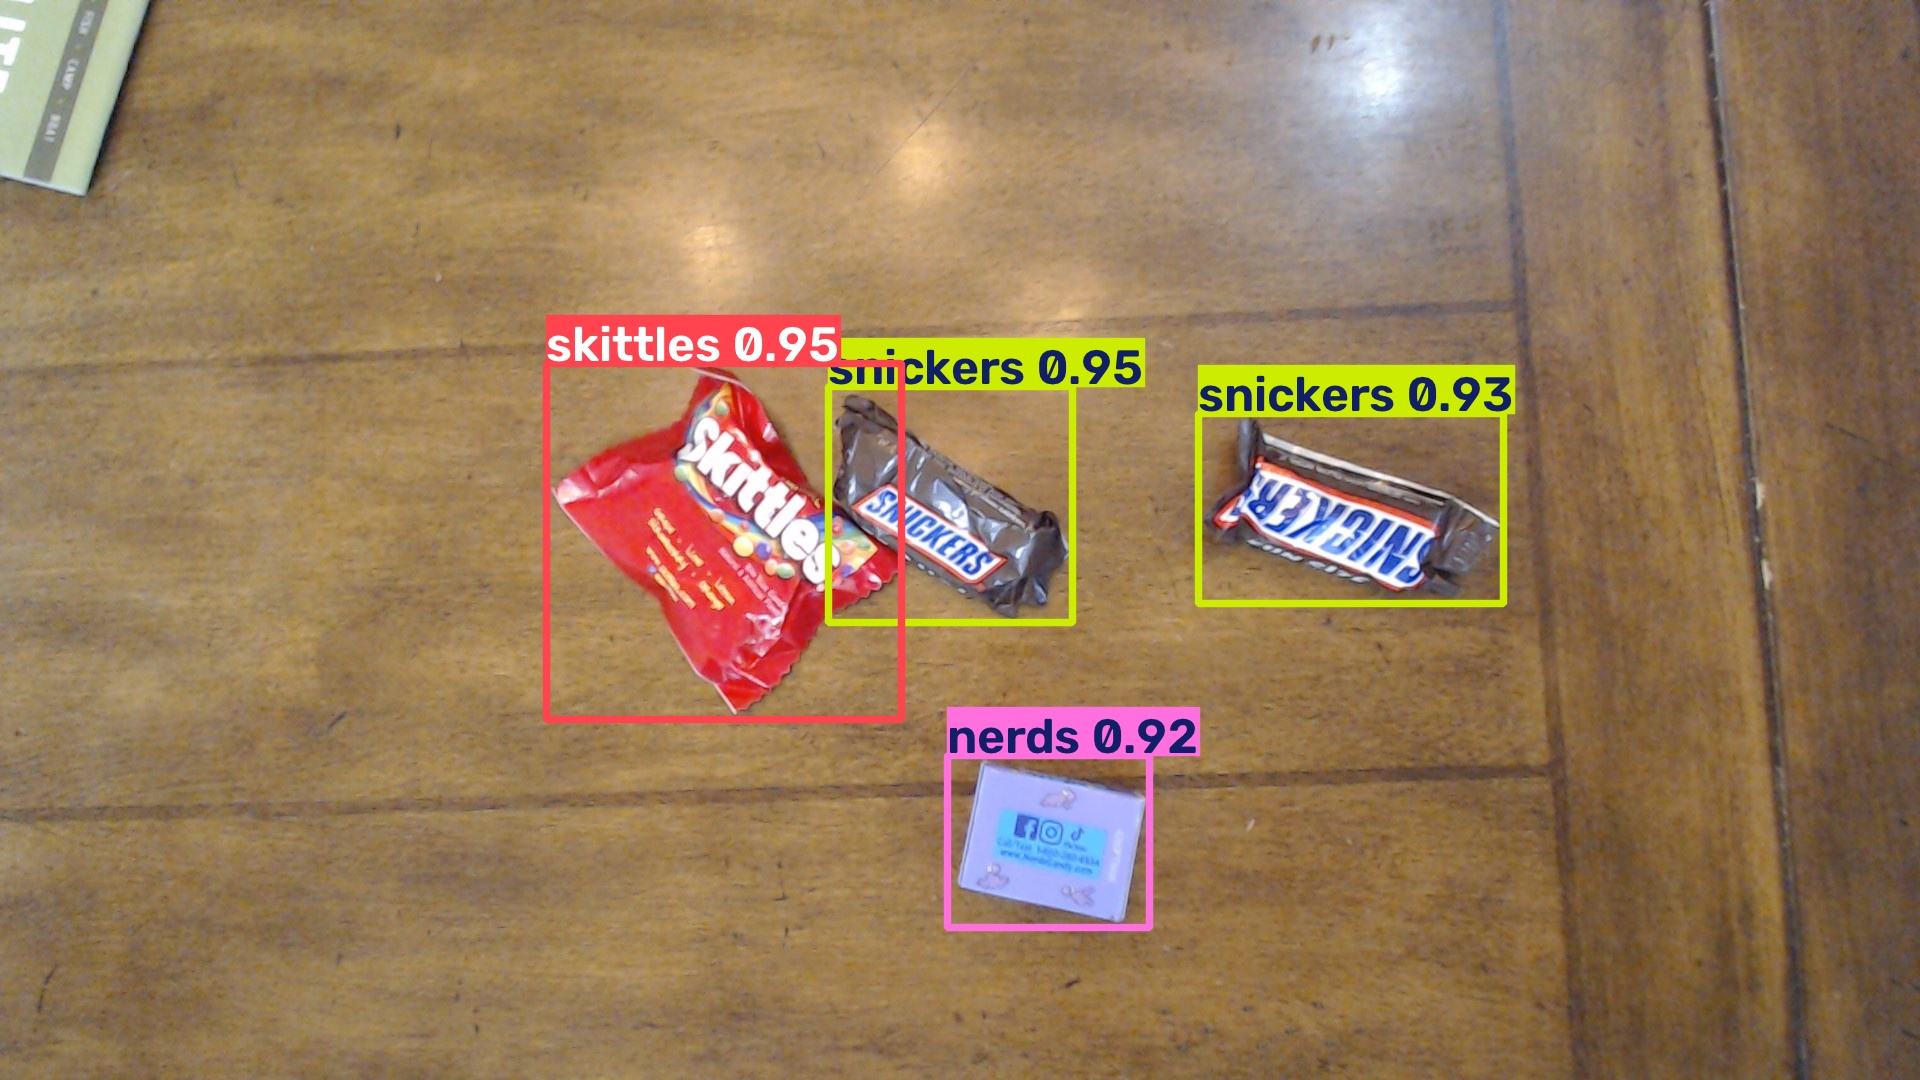

In [ ]:
import os
from ultralytics import YOLO
from IPython.display import Image, display

# 1. Path to your own uploaded image (change this to your image file's path)
image_path = '/content/data/images/09563069-candy_12.jpg'

# 2. Automatically load the best weights from your training session
runs = [os.path.join('/content/runs/detect', d) for d in os.listdir('/content/runs/detect') if d.startswith('train')]
latest_run = max(runs, key=os.path.getmtime) if runs else '/content/runs/detect/train'
best_weights = os.path.join(latest_run, 'weights/best.pt')

if os.path.exists(image_path):
    # 3. Load model and run prediction
    model = YOLO(best_weights)
    results = model.predict(source=image_path, save=True, project='/content/runs/detect', name='my_predictions', exist_ok=True)

    # 4. Find the saved result image and display it
    saved_image_path = os.path.join(results[0].save_dir, os.path.basename(image_path))
    print(f"Result saved to: {saved_image_path}")
    display(Image(filename=saved_image_path, height=400))
else:
    print(f"Please upload an image to {image_path} or update the path in the code to point to your image!")